# Task 4 — NLP Sentiment Classification on Customer Reviews (TF-IDF)
**Datheon Machine Learning & Data Science Internship · Difficulty: intermediate**

**Goal.** Clean raw review text, convert it to TF-IDF features and classify the review as **positive** or **negative** with Multinomial Naive Bayes and Logistic Regression.

### Important note about the dataset
The official Datheon file (`data/sentiment_reviews.csv`) was downloaded and inspected. **It contains only 10 reviews** (5 positive, 4 negative, 1 neutral), which is far too few to train a model or to create a meaningful 80/20 test set. The task description explicitly allows "customer product **or movie** review records", so this notebook is transparent about using two sources:

| Role | Dataset | Size |
|---|---|---|
| **Training + main benchmark** | NLTK `movie_reviews` corpus (public, labelled) | 2,000 reviews (1,000 pos / 1,000 neg) |
| **External sanity check** | Datheon starter file (positive/negative rows only) | 9 reviews |

Nothing is hidden or replaced silently: both are loaded below, and the Datheon file is kept in `data/` and evaluated separately.

## 1. Import libraries

In [1]:
import sys, json, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent                      # repository root (notebook is run from its own task folder)
sys.path.insert(0, str(ROOT / "src"))         # makes the shared `datheon_ml` helpers importable

import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

from datheon_ml import sentiment as S
from datheon_ml.sentiment import (clean_text, build_pipelines, predict_sentiment,
                                  load_movie_reviews, load_datheon_sample, ensure_nltk)

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
RESULTS, MODELS, DATA = Path("results"), Path("models"), Path("data")
RESULTS.mkdir(exist_ok=True); MODELS.mkdir(exist_ok=True)
ensure_nltk()                                  # stopwords, WordNet, movie_reviews (downloaded once)
print("Libraries and NLTK resources ready.")

Libraries and NLTK resources ready.


## 2. Load the datasets

In [2]:
datheon_raw = pd.read_csv(DATA / "sentiment_reviews.csv")
print("Datheon starter file shape:", datheon_raw.shape)
display(datheon_raw)

Datheon starter file shape: (10, 3)


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative
5,6,Customer support helped resolve my setup quest...,positive
6,7,Delivery was slow and package was missing one ...,negative
7,8,Clean interface and intuitive controls. Highly...,positive
8,9,"Not worth the money, plenty of better alternat...",negative
9,10,Great value and durable build. Would definitel...,positive


In [3]:
movies = load_movie_reviews()
movies.to_csv(DATA / "movie_reviews.csv", index=False)       # cached copy (git-ignored)
print("Movie-review corpus shape:", movies.shape)
movies.head(3)

Movie-review corpus shape: (2000, 2)


,text,sentiment
0,"plot : two teen couples go to a church party ,...",negative
1,the happy bastard's quick movie review \ndamn ...,negative
2,it is movies like these that make a jaded movi...,negative


## 3. Data inspection

In [4]:
print("Datheon file label counts:"); display(datheon_raw["sentiment"].value_counts())
print("Movie corpus label counts:"); display(movies["sentiment"].value_counts())
movies["n_words"] = movies["text"].str.split().str.len()
display(movies["n_words"].describe().round(1))

Datheon file label counts:


sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64

Movie corpus label counts:


sentiment
negative    1000
positive    1000
Name: count, dtype: int64

count    2000.0
mean      746.3
std       328.4
min        17.0
25%       526.8
50%       696.5
75%       904.0
max      2678.0
Name: n_words, dtype: float64

## 4. Data cleaning — missing values, duplicates, neutral rows

In [5]:
print("Missing values (movies):", int(movies[["text", "sentiment"]].isna().sum().sum()))
print("Duplicate reviews (movies):", int(movies["text"].duplicated().sum()))
movies = movies.dropna(subset=["text"]).drop_duplicates(subset="text").reset_index(drop=True)

datheon = load_datheon_sample(DATA / "sentiment_reviews.csv")     # keeps positive / negative only
print(f"Datheon file: {len(datheon_raw)} rows -> {len(datheon)} after removing the neutral row (task is binary)")

Missing values (movies): 0
Duplicate reviews (movies): 0
Datheon file: 10 rows -> 9 after removing the neutral row (task is binary)


## 5–10. Text preprocessing
Each step is implemented in `src/datheon_ml/sentiment.py::clean_text` and applied to every review:

1. **HTML cleaning** — remove tags such as `<br />`
2. **Lowercasing**
3. **Punctuation / number removal** — keep letters only
4. **Tokenisation** — split into words
5. **Stopword removal** — NLTK English stopwords, *except negations* (`not`, `no`, `never`, `nor` …) because "not good" must not become "good"
6. **Lemmatisation** — WordNet lemmatiser ("movies" → "movie")

Cleaning is stateless (each review is processed independently), so doing it before the split cannot leak information. TF-IDF, which *does* learn from data, is inside the pipeline.

In [6]:
print(inspect.getsource(clean_text))

def clean_text(text: str) -> str:
    """HTML removal -> lowercase -> punctuation removal -> tokenise -> stopwords -> lemmatise."""
    if not isinstance(text, str):
        return ""
    stops, lemmatizer = _resources()
    text = HTML_TAG.sub(" ", text)
    text = text.lower().replace("n't", " not")
    text = NON_LETTERS.sub(" ", text)
    tokens = [lemmatizer.lemmatize(t) for t in text.split() if t not in stops and len(t) > 1]
    return " ".join(tokens)



In [7]:
demo = "<br />This movie wasn't GOOD at all!!! The actors were terrible, and I won't watch it again... 10/10 would NOT recommend."
print("RAW    :", demo)
print("CLEANED:", clean_text(demo))

RAW    : <br />This movie wasn't GOOD at all!!! The actors were terrible, and I won't watch it again... 10/10 would NOT recommend.


CLEANED: movie not good actor terrible wo not watch would not recommend


In [8]:
movies["clean_text"] = movies["text"].apply(clean_text)
movies = movies[movies["clean_text"].str.len() > 0].reset_index(drop=True)
print("Reviews after cleaning:", len(movies))
display(movies[["text", "clean_text"]].head(2).assign(text=lambda d: d["text"].str[:150] + "...", clean_text=lambda d: d["clean_text"].str[:150] + "..."))

Reviews after cleaning: 2000


,text,clean_text
0,"plot : two teen couples go to a church party ,...",plot two teen couple go church party drink dri...
1,the happy bastard's quick movie review \ndamn ...,happy bastard quick movie review damn bug got ...


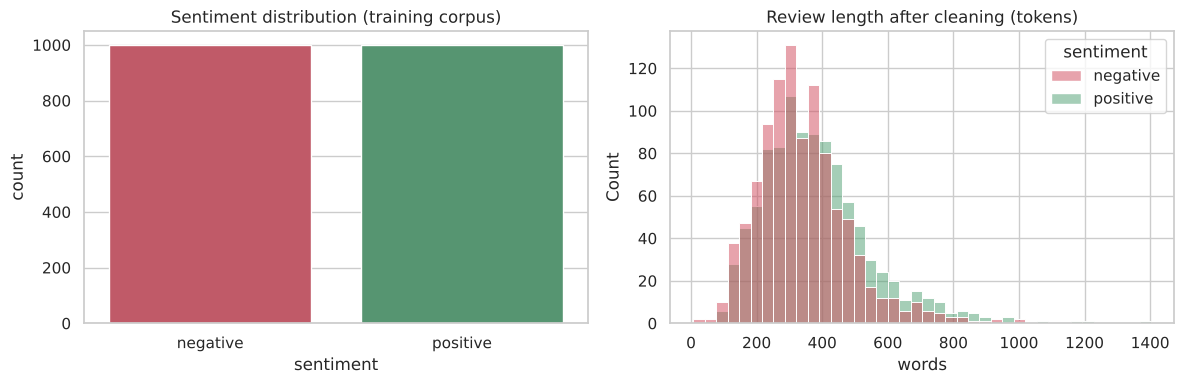

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=movies, x="sentiment", hue="sentiment", palette=["#D1495B", "#4C9F70"], order=["negative", "positive"], legend=False, ax=ax[0])
ax[0].set_title("Sentiment distribution (training corpus)")
sns.histplot(data=movies.assign(words=movies["clean_text"].str.split().str.len()), x="words", hue="sentiment",
             palette=["#D1495B", "#4C9F70"], bins=40, ax=ax[1])
ax[1].set_title("Review length after cleaning (tokens)")
plt.tight_layout(); plt.savefig(RESULTS / "sentiment_distribution.png", dpi=150); plt.show()

## 11. Train / test split (80 % / 20 %, stratified)

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    movies["clean_text"], movies["sentiment"], test_size=0.20, random_state=RANDOM_STATE, stratify=movies["sentiment"])
print("Train:", len(X_train), "| Test:", len(X_test))
print("Test label counts:", y_test.value_counts().to_dict())

Train: 1600 | Test: 400
Test label counts: {'negative': 200, 'positive': 200}


## 12. TF-IDF features
TF-IDF turns each review into a vector: a word scores high if it is frequent in that review but rare across all reviews. `TfidfVectorizer(max_features=5000)` keeps the 5,000 most informative words. It is the first step of each `Pipeline`, so its vocabulary and IDF weights are learned from **training text only**.

## 13–14. Models: Multinomial Naive Bayes and Logistic Regression

In [11]:
models = build_pipelines(RANDOM_STATE, max_features=5000)
for name, pipe in models.items():
    print(name, "->", [s for s, _ in pipe.steps])

Multinomial Naive Bayes -> ['tfidf', 'model']
Logistic Regression -> ['tfidf', 'model']


In [12]:
print(inspect.getsource(build_pipelines))      # exact model definitions (source lives in src/datheon_ml/sentiment.py)

def build_pipelines(random_state: int = 42, max_features: int = 5000) -> dict[str, Pipeline]:
    """TF-IDF + Multinomial Naive Bayes and TF-IDF + Logistic Regression."""
    return {
        "Multinomial Naive Bayes": Pipeline(
            [("tfidf", TfidfVectorizer(max_features=max_features)), ("model", MultinomialNB())]
        ),
        "Logistic Regression": Pipeline(
            [
                ("tfidf", TfidfVectorizer(max_features=max_features)),
                ("model", LogisticRegression(max_iter=1000, random_state=random_state)),
            ]
        ),
    }



In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}
for name, pipe in models.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    cv_results[name] = (scores.mean(), scores.std())
    print(f"{name:<26} 5-fold CV accuracy: {scores.mean():.4f} ± {scores.std():.4f}")

Multinomial Naive Bayes    5-fold CV accuracy: 0.8269 ± 0.0116


Logistic Regression        5-fold CV accuracy: 0.8431 ± 0.0133


## 15. Evaluation on the held-out test set

In [14]:
rows, preds = [], {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    preds[name] = pred
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred, pos_label="positive"),
                 "Recall": recall_score(y_test, pred, pos_label="positive"),
                 "F1": f1_score(y_test, pred, pos_label="positive"),
                 "CV accuracy (mean)": cv_results[name][0]})
metrics_df = pd.DataFrame(rows).set_index("Model").round(4)
metrics_df

,Accuracy,Precision,Recall,F1,CV accuracy (mean)
Model,,,,,
Multinomial Naive Bayes,0.8150,0.8316,0.79,0.8103,0.8269
Logistic Regression,0.8425,0.8186,0.88,0.8482,0.8431


In [15]:
for name, pred in preds.items():
    print("=" * 58); print(name); print("=" * 58)
    print(classification_report(y_test, pred, digits=3))

Multinomial Naive Bayes
              precision    recall  f1-score   support

    negative      0.800     0.840     0.820       200
    positive      0.832     0.790     0.810       200

    accuracy                          0.815       400
   macro avg      0.816     0.815     0.815       400
weighted avg      0.816     0.815     0.815       400

Logistic Regression
              precision    recall  f1-score   support

    negative      0.870     0.805     0.836       200
    positive      0.819     0.880     0.848       200

    accuracy                          0.843       400
   macro avg      0.844     0.843     0.842       400
weighted avg      0.844     0.843     0.842       400



### Confusion matrices

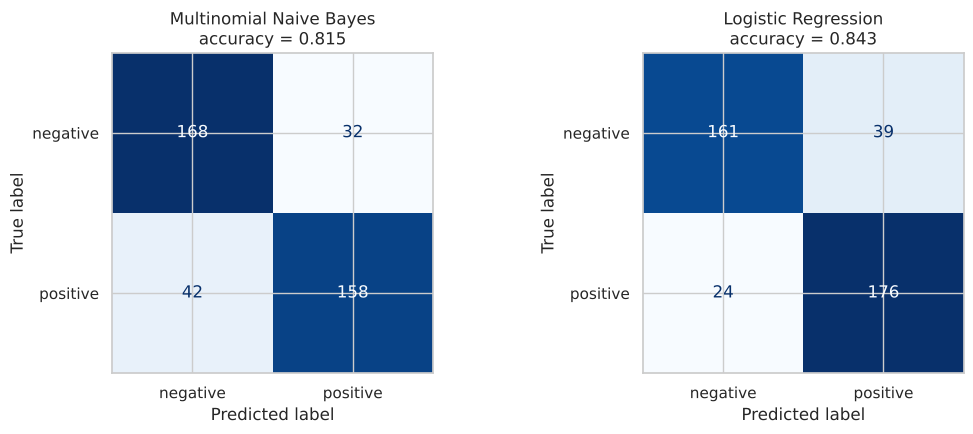

In [16]:
labels = ["negative", "positive"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=labels), display_labels=labels).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name}\naccuracy = {accuracy_score(y_test, pred):.3f}")
plt.tight_layout(); plt.savefig(RESULTS / "confusion_matrix.png", dpi=150); plt.show()

### Model comparison

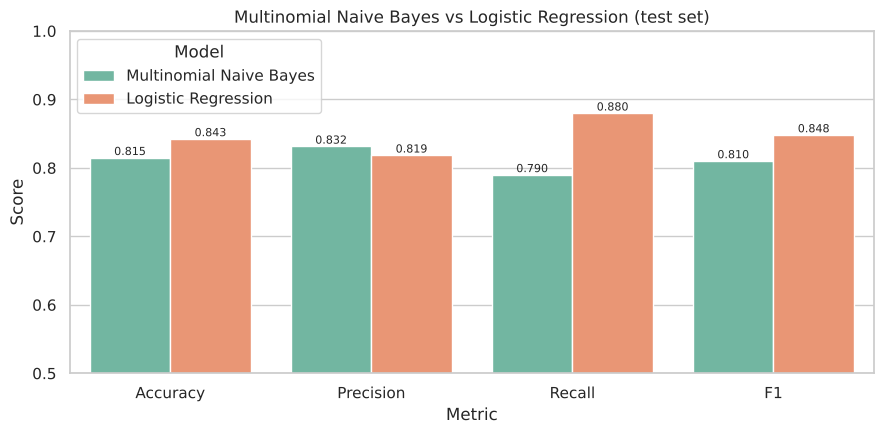

In [17]:
plot_df = metrics_df.drop(columns="CV accuracy (mean)").reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")
plt.figure(figsize=(9, 4.5))
ax = sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", palette="Set2")
ax.set_ylim(0.5, 1.0); ax.set_title("Multinomial Naive Bayes vs Logistic Regression (test set)")
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS / "model_comparison.png", dpi=150); plt.show()

### Word visualisation — which words drive the sentiment? (Logistic Regression coefficients)

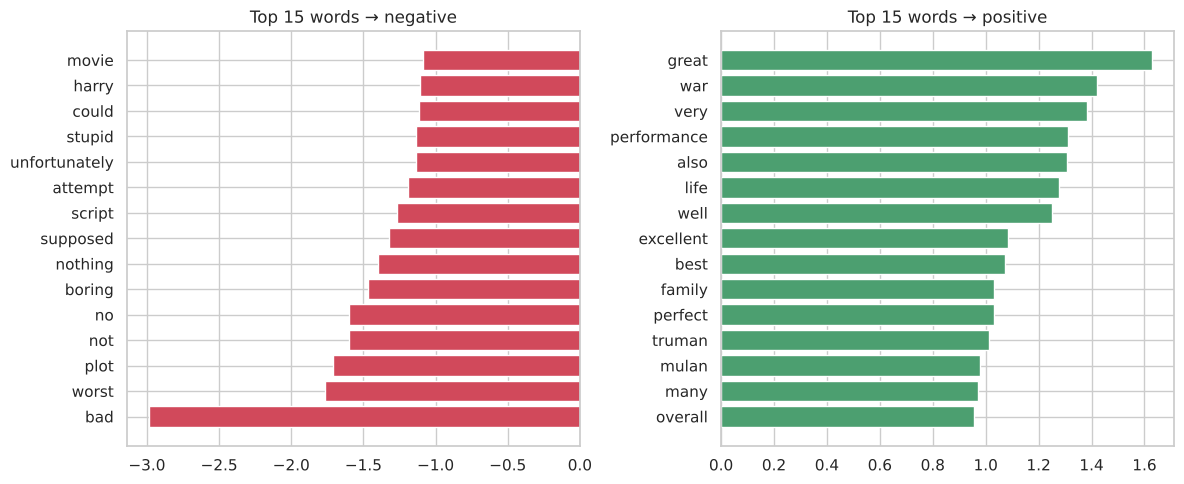

In [18]:
lr = models["Logistic Regression"]
vocab = np.array(lr.named_steps["tfidf"].get_feature_names_out())
coef = lr.named_steps["model"].coef_[0]            # positive coefficient -> "positive" class
order = np.argsort(coef)
neg_idx, pos_idx = order[:15], order[-15:]
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].barh(vocab[neg_idx], coef[neg_idx], color="#D1495B"); ax[0].set_title("Top 15 words → negative")
ax[1].barh(vocab[pos_idx], coef[pos_idx], color="#4C9F70"); ax[1].set_title("Top 15 words → positive")
plt.tight_layout(); plt.savefig(RESULTS / "top_words.png", dpi=150); plt.show()

## 16. The `predict_sentiment()` function
The function cleans the raw sentence, applies the **fitted** TF-IDF vocabulary (inside the pipeline) and returns the label with its confidence.

In [19]:
best_name = metrics_df["CV accuracy (mean)"].idxmax()        # chosen by cross-validation, not by the test set
best_model = models[best_name]
print("Model used by predict_sentiment():", best_name, "\n")

def predict_sentiment_demo(review, model=best_model):
    # 1. clean the input  2. TF-IDF + model (both inside the fitted pipeline)  3. return label + confidence
    return predict_sentiment(review, model)

print(inspect.getsource(S.predict_sentiment))

Model used by predict_sentiment(): Logistic Regression 

def predict_sentiment(review: str, model: Pipeline) -> dict:
    """Clean a raw review, vectorise it with the fitted TF-IDF and predict its sentiment."""
    cleaned = clean_text(review)
    if not cleaned:
        return {"review": review, "sentiment": "unknown", "confidence": None}
    proba = model.predict_proba([cleaned])[0]
    idx = int(proba.argmax())
    return {"review": review, "sentiment": str(model.classes_[idx]), "confidence": round(float(proba[idx]), 4)}



## 17. Custom testing — your own review sentences

In [20]:
custom_reviews = [
    "This product is amazing. I really love it.",
    "This is terrible. I completely regret buying it.",
    "Absolutely fantastic experience, great quality and fast delivery!",
    "Worst purchase ever, it broke after one day.",
    "The film was not good at all.",
    "A brilliant, moving story with superb acting.",
    "Boring plot, bad acting and a complete waste of time.",
]
out = pd.DataFrame([predict_sentiment(r, best_model) for r in custom_reviews])
out

,review,sentiment,confidence
0,This product is amazing. I really love it.,positive,0.5981
1,This is terrible. I completely regret buying it.,negative,0.5626
2,"Absolutely fantastic experience, great quality...",positive,0.6697
3,"Worst purchase ever, it broke after one day.",negative,0.5866
4,The film was not good at all.,positive,0.5165
5,"A brilliant, moving story with superb acting.",positive,0.6756
6,"Boring plot, bad acting and a complete waste o...",negative,0.9307


**Honest reading of these results.** The model gets most sentences right, but confidence is modest (0.52-0.67 on short sentences) and the negated sentence *"The film was not good at all."* is classified wrongly. This is a known weakness of unigram TF-IDF: it sees `good` as a positive word and cannot fully model the negation. Adding bigrams (`ngram_range=(1, 2)`) or a transformer model is the standard next step (listed under future improvements).

### Interactive helper
Run this cell and type your own sentences (type `quit` to stop). It is left commented out so that *Run All* never waits for keyboard input.

In [21]:
def interactive_demo(model=best_model):
    while True:
        text = input("Enter a review (or 'quit'): ").strip()
        if text.lower() in {"quit", "exit", ""}:
            break
        print(predict_sentiment(text, model))

# interactive_demo()          # <- remove the leading '#' to try it

## 18. External check on Datheon's own starter reviews
These 9 reviews are **product** reviews, while the model was trained on **movie** reviews, so this tests cross-domain transfer. With only 9 rows, the result is anecdotal and must not be read as a reliable accuracy figure.

In [22]:
ext = datheon.copy()
ext_pred = [predict_sentiment(t, best_model) for t in ext["text"]]
ext["predicted"] = [p["sentiment"] for p in ext_pred]
ext["confidence"] = [p["confidence"] for p in ext_pred]
ext["correct"] = ext["predicted"] == ext["sentiment"]
display(ext[["text", "sentiment", "predicted", "confidence", "correct"]])
ext_acc = float(ext["correct"].mean())
print(f"Accuracy on the {len(ext)} Datheon reviews: {ext_acc:.3f} ({int(ext['correct'].sum())}/{len(ext)})")

,text,sentiment,predicted,confidence,correct
0,"The product quality is exceptional, exceeded a...",positive,positive,0.5387,True
1,Terrible customer service and the item arrived...,negative,negative,0.5362,True
2,"Absolutely love this! Easy to setup, robust, a...",positive,positive,0.5977,True
3,Stopped working after two days. Extremely disa...,negative,positive,0.5923,False
4,Customer support helped resolve my setup quest...,positive,negative,0.5145,False
5,Delivery was slow and package was missing one ...,negative,positive,0.5195,False
6,Clean interface and intuitive controls. Highly...,positive,positive,0.5990,True
7,"Not worth the money, plenty of better alternat...",negative,negative,0.5137,True
8,Great value and durable build. Would definitel...,positive,positive,0.6727,True


Accuracy on the 9 Datheon reviews: 0.667 (6/9)


## 19. Save models and metrics

In [23]:
joblib.dump(models["Multinomial Naive Bayes"], MODELS / "naive_bayes.joblib")
joblib.dump(models["Logistic Regression"], MODELS / "logistic_regression.joblib")
joblib.dump(best_model, MODELS / "best_sentiment_model.joblib")
summary = {"training_corpus": "NLTK movie_reviews (2,000 labelled reviews)", "reviews_used": int(len(movies)),
           "train_rows": int(len(X_train)), "test_rows": int(len(X_test)), "best_model_by_cv": best_name,
           "models": metrics_df.to_dict(orient="index"),
           "datheon_sample": {"rows_total": int(len(datheon_raw)), "rows_used": int(len(ext)), "accuracy": round(ext_acc, 4)}}
(RESULTS / "metrics.json").write_text(json.dumps(summary, indent=2))
print("Saved:", sorted(p.name for p in MODELS.iterdir()))

Saved: ['best_sentiment_model.joblib', 'logistic_regression.joblib', 'naive_bayes.joblib']


## 20. Conclusions

In [24]:
print(metrics_df.to_string())
print(f"\nSelected by cross-validation: {best_name}")
print(f"Datheon starter reviews (9 rows, cross-domain): {ext_acc:.0%} correct")

                         Accuracy  Precision  Recall      F1  CV accuracy (mean)
Model                                                                           
Multinomial Naive Bayes    0.8150     0.8316    0.79  0.8103              0.8269
Logistic Regression        0.8425     0.8186    0.88  0.8482              0.8431

Selected by cross-validation: Logistic Regression
Datheon starter reviews (9 rows, cross-domain): 67% correct


**Limitations.** The Datheon file is too small for training; the benchmark corpus is movie reviews (a different domain from product reviews); bag-of-words TF-IDF ignores word order and sarcasm; neutral sentiment is not modelled.
**Next steps.** Add n-grams (1–2), tune `C`/`alpha`, train on a real product-review corpus, compare with a transformer model (e.g. DistilBERT) and extend to Urdu / Roman-Urdu text.